In [1]:
import pandas as pd
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt

In [6]:
eurcad = yf.download("EURCAD=X", period="5y")[["Close"]]
eurcad_returns = eurcad.pct_change(fill_method=None).dropna() *100


[*********************100%***********************]  1 of 1 completed


In [12]:
model = arch_model(eurcad_returns, vol="Garch", p=1, q=1)
model_fit = model.fit(disp="off")

print(model_fit.summary())

                       Constant Mean - GARCH Model Results                       
Dep. Variable:     ('Close', 'EURCAD=X')   R-squared:                       0.000
Mean Model:                Constant Mean   Adj. R-squared:                  0.000
Vol Model:                         GARCH   Log-Likelihood:               -618.089
Distribution:                     Normal   AIC:                           1244.18
Method:               Maximum Likelihood   BIC:                           1264.86
                                           No. Observations:                 1300
Date:                   Sun, Mar 15 2026   Df Residuals:                     1299
Time:                           04:09:35   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         3.5379e-03  1.014

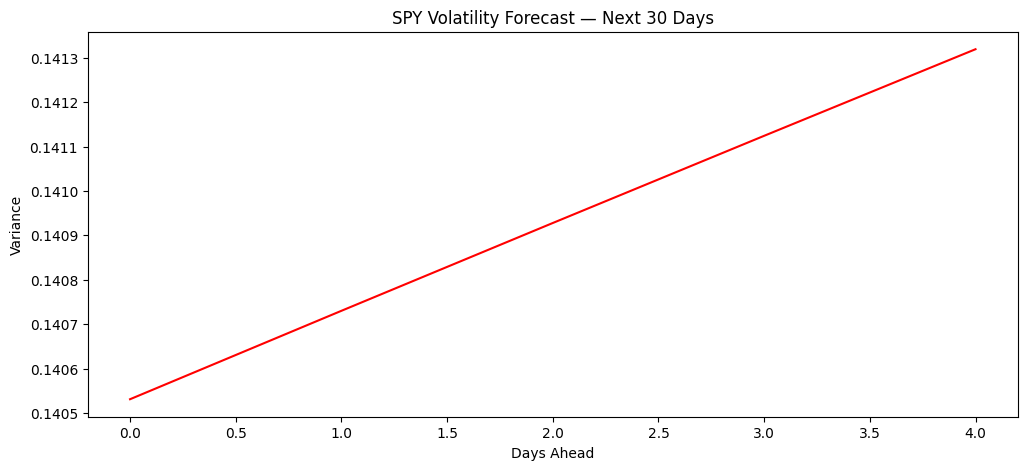

In [13]:
forecast = model_fit.forecast(horizon=5)
variance_forecast = forecast.variance.iloc[-1]

plt.figure(figsize=(12,5))
plt.plot(variance_forecast.values, color="red")
plt.title("SPY Volatility Forecast — Next 30 Days")
plt.xlabel("Days Ahead")
plt.ylabel("Variance")
plt.show()